# Does the explicit-mention rewrite help recall? A per-property audit

**Question.** LMEnt S6.2 proposes a causal intervention: rewrite every *implicit*
entity mention (pronoun, alias, descriptor — anything found only by coreference) to
the entity's canonical name, then pretrain on the rewritten corpus. If knowledge
acquisition is bottlenecked by mention ambiguity, recall should go up. This notebook
asks **for which PopQA relations it went up, for which it went down, and why**.

## Which artifacts, and why

| role | artifact |
|---|---|
| regular corpus | `data/artifacts/recall/regular_corpus/LMEnt-170M-1E/recall_step109672_15shot_recallonly.parquet` |
| translated corpus | `data/artifacts/recall/explicit_mention_corpus/explicit_170M_1E/recall_step113720_15shot_recallonly.parquet` |

Both are **170M, end of epoch 1, 15-shot, recall-only**. The step numbers differ
(109672 vs 113720) only because the rewrite lengthens documents, so one epoch over
the explicit corpus is ~3.7% more optimizer steps. Crucially these two files are
**row-for-row and prompt-for-prompt identical** (asserted below), which makes every
comparison here *paired*: same 14 248 facts, same 15-shot context, same scorer. The
only thing that differs is the corpus the model was pretrained on.

### Why not `explicit_170M_1E_wiki`

`explicit_170M_1E_wiki` is the same model and the same checkpoint, evaluated on a
*different question set*: the disambiguation block in `emlib/data.py`
(`load_popqa_df`, currently commented out) drops duplicate questions, rewrites
ambiguous subjects to their `s_wiki_title` (`Madison` → `Madison, South Dakota`),
and drops rows where the wiki title leaks the answer. That yields 13 609 rows, of
which 1 099 carry *different prompts*. It is the cleaner eval set — but no
regular-corpus 170M artifact was produced under it, so pairing against the baseline
is impossible. Use it for absolute numbers on the explicit model; use the plain
directory (as here) for any base-vs-explicit comparison.

## Headline

Overall recall **falls**, 3.96% → 2.61% on scoreable facts. The per-property picture
is not uniform decay: three relations lose catastrophically (`capital` −24pp,
`religion` −15pp, `sport` −12pp), two high-baseline relations are untouched
(`country`, `capital of`), and `genre` appears to gain +2.9pp — but §5 shows that
gain is a **substring-match artifact**, not knowledge.

## 1. Setup

In [1]:
import os, re, sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

REPO = Path.cwd()
while not (REPO / "explicit_mentions").is_dir() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "explicit_mentions"))
os.environ.setdefault("HF_HUB_OFFLINE", "1")          # popqa-kas is cached locally

import datasets
datasets.logging.set_verbosity_error()                 # silence the offline-cache banner

from emlib import data as D
from emlib import lment_popqa as L

RECALL = REPO / "data" / "artifacts" / "recall"
BASE_PQ = RECALL / "regular_corpus" / "LMEnt-170M-1E" / "recall_step109672_15shot_recallonly.parquet"
EXPL_PQ = RECALL / "explicit_mention_corpus" / "explicit_170M_1E" / "recall_step113720_15shot_recallonly.parquet"
REVIEW  = REPO / "explicit_mentions" / "rewrite_review.md"
print(REPO)

C:\Users\rotem\master\nlp\NLPFinalProject


In [2]:
# Palette shared with the other notebooks in this repo. BLUE/ORANGE is the
# validated diverging pair (OKLab dE 33.6 normal, 24.7 deuteranopia); the
# midpoint is a neutral gray, never a third hue. Never pair ORANGE with RED.
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, PURPLE, NEUTRAL = "#2a78d6", "#eb6834", "#7b5ea7", "#f0efec"
BETTER, WORSE = BLUE, ORANGE

plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
pp = lambda x: f"{100*x:+.1f}pp"

## 2. Load, and prove the two runs are paired

If any assertion below fires, the per-property deltas are not paired and the
McNemar tests in §4 are invalid.

In [3]:
COLS = ["id", "step", "correct", "excluded", "prompt", "generation"]
base = pd.read_parquet(BASE_PQ, columns=COLS)
expl = pd.read_parquet(EXPL_PQ, columns=COLS)

assert (base.id.values == expl.id.values).all(),             "fact order differs"
assert (base.prompt.values == expl.prompt.values).all(),     "prompts differ -> not a corpus-only comparison"
assert (base.excluded.values == expl.excluded.values).all(), "exclusion masks differ"
print(f"{len(base):,} facts, identical prompts, steps {base.step.iloc[0]} (base) vs {expl.step.iloc[0]} (explicit)")

14,248 facts, identical prompts, steps 109672 (base) vs 113720 (explicit)


In [4]:
qa = D.load_popqa_df()

df = (base.rename(columns={"correct": "base", "generation": "g_base"})[["id", "base", "excluded", "g_base"]]
        .merge(expl.rename(columns={"correct": "expl", "generation": "g_expl"})[["id", "expl", "g_expl"]], on="id")
        .merge(qa, on="id"))

# `excluded` = a gold alias already appears in the prompt, so the fact is
# unmeasurable. It is identical in both runs; drop it once.
n_excl = int(df.excluded.sum())
df = df[~df.excluded].reset_index(drop=True)
print(f"{n_excl} excluded -> {len(df):,} scoreable facts, {df.prop.nunique()} relations")
df.head(3)[["id", "prop", "subj", "obj", "base", "expl"]]

317 excluded -> 13,931 scoreable facts, 16 relations


,id,prop,subj,obj,base,expl
0,4222362,occupation,George Rankin,politician,False,False
1,4725190,occupation,John Mayne,journalist,False,False
2,4382392,occupation,Henry Feilden,politician,False,False


## 3. Overall effect

In [5]:
b, e = df.base.mean(), df.expl.mean()
n01 = int(((df.base == 0) & (df.expl == 1)).sum())   # gained by translation
n10 = int(((df.base == 1) & (df.expl == 0)).sum())   # lost to translation
mcn = stats.binomtest(n01, n01 + n10, 0.5)           # exact McNemar

print(f"regular corpus     {b:.4f}  ({int(df.base.sum()):>4d} / {len(df):,})")
print(f"translated corpus  {e:.4f}  ({int(df.expl.sum()):>4d} / {len(df):,})")
print(f"delta              {pp(e - b)}   (relative {100*(e-b)/b:+.1f}%)")
print(f"\ndiscordant pairs: {n01} gained, {n10} lost  ->  exact McNemar p = {mcn.pvalue:.3g}")
print(f"95% CI on P(gain | discordant): {mcn.proportion_ci().low:.3f}-{mcn.proportion_ci().high:.3f}  (0.5 = no effect)")

regular corpus     0.0396  ( 551 / 13,931)


translated corpus  0.0261  ( 364 / 13,931)
delta              -1.3pp   (relative -33.9%)

discordant pairs: 225 gained, 412 lost  ->  exact McNemar p = 1.15e-13
95% CI on P(gain | discordant): 0.316-0.392  (0.5 = no effect)


The rewrite costs about a third of the model's already-thin PopQA recall, and the
effect is far outside chance. But 578 facts *did* flip in its favour, so the sign is
not uniform — that is what §4 unpacks.

## 4. Per-property effect

For each relation: accuracy under each corpus, the paired delta, the discordant
counts, and an **exact McNemar test** (binomial on the discordant pairs), with
Benjamini–Hochberg FDR control across the 16 relations.

In [6]:
rows = []
for prop, g in df.groupby("prop"):
    g01 = int(((g.base == 0) & (g.expl == 1)).sum())
    g10 = int(((g.base == 1) & (g.expl == 0)).sum())
    p = stats.binomtest(g01, g01 + g10, 0.5).pvalue if (g01 + g10) else 1.0
    rows.append(dict(prop=prop, n=len(g), acc_base=g.base.mean(), acc_expl=g.expl.mean(),
                     delta=g.expl.mean() - g.base.mean(), gained=g01, lost=g10, p=p))

per_prop = pd.DataFrame(rows).sort_values("delta", ascending=False).reset_index(drop=True)
per_prop["q_bh"] = stats.false_discovery_control(per_prop.p.values)
per_prop["sig"] = np.where(per_prop.q_bh < 0.05, "*", "")
per_prop.style.format({"acc_base": "{:.3f}", "acc_expl": "{:.3f}", "delta": "{:+.3f}",
                       "p": "{:.2g}", "q_bh": "{:.2g}"}).hide(axis="index")

prop,n,acc_base,acc_expl,delta,gained,lost,p,q_bh,sig
genre,1611,0.006,0.035,+0.029,51,5,1.2e-10,6.2e-10,*
mother,186,0.000,0.011,+0.011,2,0,0.5,1,
occupation,531,0.000,0.008,+0.008,4,0,0.12,0.33,
screenwriter,1995,0.001,0.005,+0.004,9,2,0.065,0.21,
author,1504,0.003,0.004,+0.001,4,2,0.69,1,
producer,1517,0.001,0.002,+0.001,3,2,1,1,
place of birth,577,0.002,0.002,+0.000,1,1,1,1,
director,1998,0.000,0.000,+0.000,0,0,1,1,
father,530,0.004,0.002,-0.002,1,2,1,1,
country,800,0.139,0.136,-0.003,78,80,0.94,1,


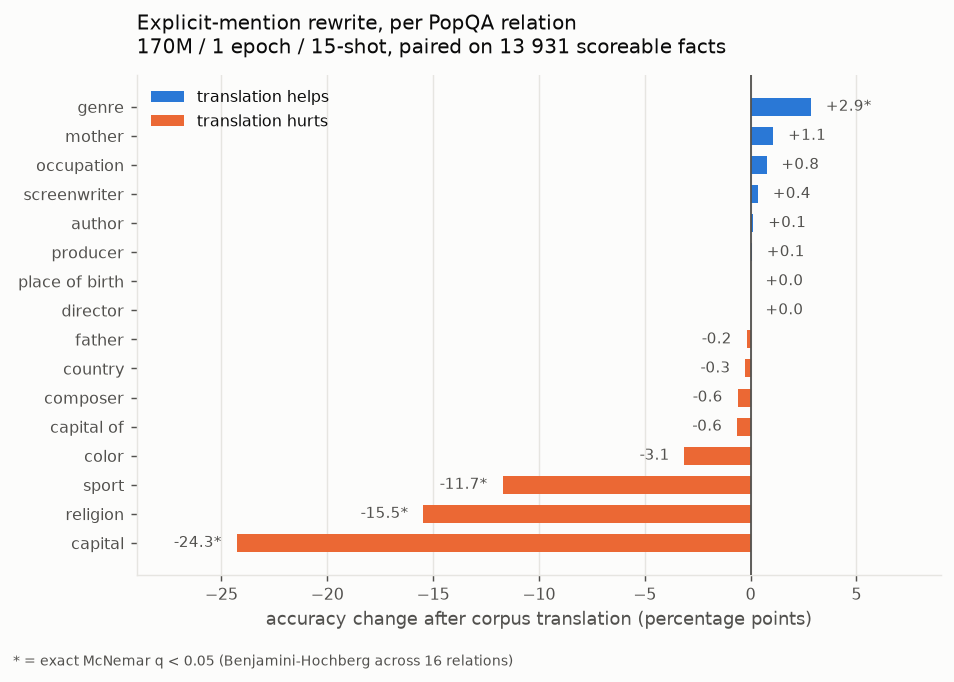

In [7]:
d = per_prop.sort_values("delta")
fig, ax = plt.subplots(figsize=(7.4, 5.2))
colors = [BETTER if v > 0 else (WORSE if v < 0 else GRID) for v in d.delta]
ax.barh(d.prop, 100 * d.delta, color=colors, height=0.62, zorder=3)
ax.axvline(0, color=INK2, lw=1, zorder=4)
ax.xaxis.grid(True, zorder=0); ax.set_axisbelow(True)

for y, (v, n, s) in enumerate(zip(d.delta, d.n, d.sig)):
    off = 0.7 if v >= 0 else -0.7
    ax.text(100 * v + off, y, f"{100*v:+.1f}{s}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8.5, color=INK2)

ax.set_xlim(-29, 9)
ax.set_xlabel("accuracy change after corpus translation (percentage points)")
ax.set_title("Explicit-mention rewrite, per PopQA relation\n"
             "170M / 1 epoch / 15-shot, paired on 13 931 scoreable facts", loc="left", pad=12)
ax.legend(handles=[Patch(facecolor=BETTER, label="translation helps"),
                   Patch(facecolor=WORSE,  label="translation hurts")],
          loc="upper left", fontsize=9)
fig.text(0.015, 0.005, "* = exact McNemar q < 0.05 (Benjamini-Hochberg across 16 relations)",
         fontsize=8, color=INK2)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

### 4.1 Winners and losers

**Helped (significant): `genre` only.** 0.6% → 3.5%, 51 facts gained against 5 lost.
Read §5 before believing it.

**Hurt (significant): `capital`, `religion`, `sport`.**

| relation | template | base | explicit | delta |
|---|---|---|---|---|
| `capital` | `The capital of {} is` | 30.1% | 5.8% | −24.3pp |
| `religion` | `The religion of {} is` | 24.6% | 9.1% | −15.5pp |
| `sport` | `The sport {} plays is` | 23.1% | 11.3% | −11.7pp |

Everything else is flat, but most of the remaining relations sit at ~0% under *both*
corpora (`director` 0.0/0.0, `occupation` 0.0/0.8%, `mother` 0.0/1.1%). A 170M model
after one epoch simply cannot do open-ended entity-naming relations, so those rows
carry no information about the rewrite either way.

### 4.2 Is this just "whatever was above zero fell"?

A cheap explanation for the loser list: only relations with a non-trivial baseline
*could* lose, so the ranking may be mostly an artifact of where the headroom was.
This is largely true and worth stating plainly — but two counterexamples show it is
not the whole story.

In [8]:
head = per_prop[per_prop.acc_base > 0.10].sort_values("acc_base", ascending=False)
print("relations with a baseline above 10% -- the only ones with room to fall:\n")
print(head[["prop", "n", "acc_base", "acc_expl", "delta", "q_bh"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4f}"))

r = stats.spearmanr(per_prop.acc_base, per_prop.delta)
print(f"\nSpearman(baseline accuracy, delta) = {r.statistic:+.3f}  p={r.pvalue:.3g}")

relations with a baseline above 10% -- the only ones with room to fall:

      prop   n  acc_base  acc_expl   delta   q_bh
   capital 519    0.3006    0.0578 -0.2428 0.0000
  religion 330    0.2455    0.0909 -0.1545 0.0000
     sport 512    0.2305    0.1133 -0.1172 0.0000
capital of 314    0.1688    0.1624 -0.0064 1.0000
   country 800    0.1388    0.1363 -0.0025 1.0000

Spearman(baseline accuracy, delta) = -0.832  p=6.3e-05


Spearman(baseline, delta) = **−0.83** (p = 6e-05): headroom explains most of the
ranking, and any claim of the form "relation X is especially rewrite-sensitive"
has to clear that bar first.

It does not explain everything, though. `country` (13.9% → 13.6%) and `capital of`
(16.9% → 16.2%) start well above the floor and are **completely unmoved**, while
`capital`, starting at 30.1%, loses four fifths of its accuracy. Within the
above-10% group the effect is bimodal — three relations near-annihilated, two
untouched — which a uniform shrink cannot produce.

Note `capital` and `capital of` are inverses of each other (`The capital of Kenya is`
vs `Nairobi is the capital of`) over overlapping entities — and only one of them
breaks. That is a strong hint the failure is in *how the model answers*, not in what
it knows about those places. §5 and §6 test exactly that.

## 5. Control: is the `genre` gain real, or a substring artifact?

The olmes scorer is `max_gen_toks=15`, greedy, stop at `\n\n`, and correct iff **any
gold alias substring-matches the generation**. A model that answers with a longer,
hedgier continuation gets more chances to contain the gold string by accident — and
`genre` golds are short common nouns (`rock music`, `pop music`, `drama`) that a
rambling music-flavoured sentence will hit sooner or later.

The control: re-score both runs after truncating every generation to its first *k*
words. A real knowledge gain survives truncation; a verbosity artifact does not.

In [9]:
def rescore(col, k):
    # Re-apply the olmes substring scorer to the first k words of a generation.
    return np.array([L.is_correct(r, " ".join(str(r[col]).split()[:k])) for _, r in df.iterrows()], bool)

for k in (3, 5, 15):
    sb, se = rescore("g_base", k), rescore("g_expl", k)
    print(f"first {k:>2d} words:  base {sb.mean():.4f}   explicit {se.mean():.4f}   delta {pp(se.mean()-sb.mean())}")

df["base_k3"], df["expl_k3"] = rescore("g_base", 3), rescore("g_expl", 3)

first  3 words:  base 0.0316   explicit 0.0144   delta -1.7pp


first  5 words:  base 0.0367   explicit 0.0215   delta -1.5pp


first 15 words:  base 0.0396   explicit 0.0261   delta -1.3pp


In [10]:
ctrl = (df.groupby("prop")
          .agg(n=("base", "size"),
               d_full=("expl", "mean"), _b=("base", "mean"),
               d_k3=("expl_k3", "mean"), _b3=("base_k3", "mean")))
ctrl["delta_full"] = ctrl.d_full - ctrl._b
ctrl["delta_first3"] = ctrl.d_k3 - ctrl._b3
ctrl["surviving"] = np.where(ctrl.delta_full.abs() > 1e-9, ctrl.delta_first3 / ctrl.delta_full, np.nan)
ctrl = ctrl[["n", "delta_full", "delta_first3", "surviving"]].sort_values("delta_full", ascending=False)
ctrl.style.format({"delta_full": "{:+.4f}", "delta_first3": "{:+.4f}", "surviving": "{:.0%}"})

,n,delta_full,delta_first3,surviving
prop,,,,
genre,1611,+0.0286,+0.0012,4%
mother,186,+0.0108,+0.0108,100%
occupation,531,+0.0075,+0.0000,0%
screenwriter,1995,+0.0035,+0.0035,100%
author,1504,+0.0013,+0.0013,100%
producer,1517,+0.0007,+0.0007,100%
place of birth,577,+0.0000,+0.0017,nan%
director,1998,+0.0000,+0.0000,nan%
father,530,-0.0019,+0.0019,-100%


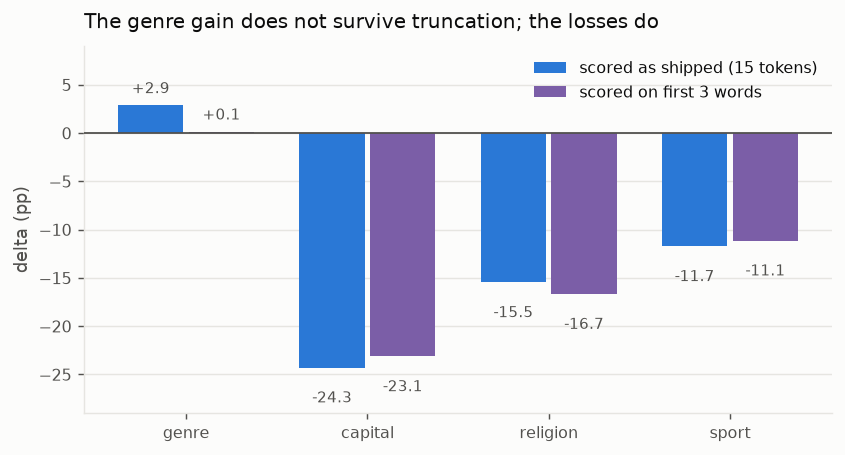

In [11]:
sub = ctrl.loc[["genre", "capital", "religion", "sport"]]
x = np.arange(len(sub)); w, gap = 0.36, 0.015     # `gap` keeps a surface sliver between paired bars
fig, ax = plt.subplots(figsize=(6.6, 3.6))
ax.bar(x - w/2 - gap, 100 * sub.delta_full,   w, color=BLUE,   label="scored as shipped (15 tokens)", zorder=3)
ax.bar(x + w/2 + gap, 100 * sub.delta_first3, w, color=PURPLE, label="scored on first 3 words",       zorder=3)
ax.axhline(0, color=INK2, lw=1, zorder=4)
ax.set_xticks(x); ax.set_xticklabels(sub.index)
ax.set_ylim(-29, 9)
ax.set_ylabel("delta (pp)"); ax.yaxis.grid(True); ax.set_axisbelow(True)
ax.set_title("The genre gain does not survive truncation; the losses do", loc="left", pad=10)
ax.legend(fontsize=9, loc="upper right")
for xs, vals in [(x - w/2 - gap, sub.delta_full), (x + w/2 + gap, sub.delta_first3)]:
    for xi, v in zip(xs, vals):
        ax.text(xi, 100*v + (0.9 if v > 0 else -2.4), f"{100*v:+.1f}",
                ha="center", va="bottom" if v > 0 else "top", fontsize=8.5, color=INK2)
plt.tight_layout(); plt.show()

**`genre` +2.86pp collapses to +0.12pp** once the generation is cut to three words —
96% of the "gain" was gold text appearing *late* in a longer answer. The three big
losses are unchanged under truncation (`capital` −23.1pp, `religion` −16.7pp,
`sport` −11.1pp), so they are not a scoring quirk.

Conclusion: **the translated corpus produced no relation with a defensible recall
gain.** The mean generation grew from 4.30 to 5.34 words (both runs are capped at
`max_gen_toks=15`, so this is the model failing to terminate, not a longer budget),
and that is enough to inflate loose substring matching on broad-vocabulary answers.

In [12]:
for name, col in [("regular", "g_base"), ("translated", "g_expl")]:
    g = df[col]
    print(f"{name:>11}: mean {g.str.split().str.len().mean():.2f} words / "
          f"{g.str.len().mean():.1f} chars,  <=4 words {(g.str.split().str.len() <= 4).mean():.1%}")

    regular: mean 4.30 words / 23.1 chars,  <=4 words 66.1%
 translated: mean 5.34 words / 29.7 chars,  <=4 words 66.1%


## 6. What the losses actually look like

The three broken relations do not degrade gracefully — the translated model falls
into a **mode-collapsed answer** for each one.

In [13]:
for prop in ["capital", "religion", "sport", "genre"]:
    g = df[df.prop == prop]
    print("=" * 96)
    print(f"{prop.upper()}   n={len(g)}   base {g.base.mean():.3f} -> explicit {g.expl.mean():.3f}")
    for label, col in [("regular   ", "g_base"), ("translated", "g_expl")]:
        top = g[col].str.strip().value_counts().head(3)
        print(f"  most common {label} answers: " +
              " | ".join(f"{v!r} x{c}" for v, c in top.items()))

CAPITAL   n=519   base 0.301 -> explicit 0.058
  most common regular    answers: 'in the Philippines' x40 | 'in the United States' x14 | 'in the South Pacific' x9
  most common translated answers: 'in is in is in is in is in is in is in is in' x54 | 'in is the capital of the United States. The capital of the United States' x7 | 'in is the capital of the United Kingdom. The capital of the United Kingdom' x7
RELIGION   n=330   base 0.245 -> explicit 0.091
  most common regular    answers: 'Christianity' x116 | 'Catholicism' x47 | 'Islam' x43
  most common translated answers: 'Catholicism.' x198 | 'Catholic.' x14 | 'Christianity' x8
SPORT   n=512   base 0.230 -> explicit 0.113
  most common regular    answers: 'rugby' x96 | 'football' x56 | 'the sport of football' x41
  most common translated answers: 'rugby union.' x97 | 'a sport that is played by people who are not professional athletes. The sport' x18 | 'a form of rugby union. The sport is a form of rugby union.' x11
GENRE   n=1611   b

In [14]:
def flips(prop, direction, k=8):
    g = df[df.prop == prop]
    f = g[(g.base == 0) & (g.expl == 1)] if direction == "gain" else g[(g.base == 1) & (g.expl == 0)]
    print(f"\n{prop.upper()} -- {len(f)} facts {'gained' if direction=='gain' else 'lost'}")
    print(f"  {'subject':<32} {'gold':<20} {'regular ->':<22} translated")
    for _, r in f.head(k).iterrows():
        print(f"  {str(r.subj)[:31]:<32} {str(r.obj)[:19]:<20} {r.g_base.strip()[:20]:<22} {r.g_expl.strip()[:34]}")

flips("capital", "loss"); flips("religion", "loss"); flips("sport", "loss"); flips("genre", "gain")


CAPITAL -- 133 facts lost
  subject                          gold                 regular ->             translated
  Czechoslovakia                   Prague               Prague                 in is the capital of the Czech Rep
  Northern Territory               Darwin               Darwin                 in is the capital of the Northern 
  Czech Republic                   Prague               Prague                 in is in is in is in is in is in i
  Kyrgyzstan                       Bishkek              in the city of Bishk   in is Kyrgyzstan
  Kingdom of France                Paris                in is Paris            in is the capital of the French Re
  Grand Duchy of Finland           Helsinki             Helsinki               in is Finland. The capital of Gran
  German Democratic Republic       East Berlin          East Berlin            in is the capital of the German De
  European Union                   City of Brussels     Brussels               in is France

RELIGION -

Three distinct failure modes, and they line up with three different things the
rewrite does to the corpus:

1. **`capital` — template collapse.** The translated model emits degenerate
   continuations: `"in is in is in is in is…"` for 54 of 519 facts, and
   `"in is the capital of the United States. The capital of…"` for others. It has
   stopped producing an *entity* in the answer slot at all. `Czechoslovakia → Prague`
   becomes `Czechoslovakia → "in is the capital of the C…"`. Meanwhile its inverse
   `capital of` (which asks `Nairobi is the capital of`) still answers with country
   names and is unharmed.

2. **`religion` — prior collapse.** 198 of 330 religion facts get the single answer
   `"Catholicism."` This costs the model every non-Catholic fact (`Paul → Judaism`
   answered `Catholicism.`, `Silla → Buddhism` answered `Sillaism.`) *and* the
   Catholic ones, because the gold alias is `Catholic Church` and `Catholicism` does
   not substring-match it.

3. **`sport` — prior collapse plus definition-hedging.** 97 facts answer
   `"rugby union."` and 18 answer `"a sport that is played by people who are not
   professional athletes."` The overwhelmingly modal gold is `association football`;
   the model now describes the *category* instead of naming the sport.

All three are failures to put a short, canonical entity string in the answer slot.
That is precisely the behaviour the rewrite alters at the corpus level, which §7
makes concrete.

### 6.1 Did `genre` win by shotgunning every genre it knows?

The obvious reading of *"a blend of rock, jazz, and funk"* is that the model sprays
candidate genres and substring matching catches one. Test it directly: count how
many **distinct gold genre strings** (the 275 that appear as `obj` somewhere in this
relation) each generation contains.

In [15]:
gen = df[df.prop == "genre"].copy()
vocab = sorted({str(o).lower() for o in gen.obj if len(str(o)) > 3})
n_hits = lambda t: sum(1 for v in vocab if v in str(t).lower())
gen["hits_base"], gen["hits_expl"] = gen.g_base.map(n_hits), gen.g_expl.map(n_hits)

print(f"{len(vocab)} distinct gold genre strings in this relation\n")
print(f"{'':<12}{'mean hits':>10}{'>=2 golds':>12}{'>=3 golds':>12}")
for label, c in [("regular", "hits_base"), ("translated", "hits_expl")]:
    print(f"{label:<12}{gen[c].mean():>10.3f}{(gen[c] >= 2).mean():>11.1%}{(gen[c] >= 3).mean():>12.1%}")

gained = gen[(gen.base == 0) & (gen.expl == 1)]
print(f"\nthe {len(gained)} gained facts, by number of gold genres named in the winning answer:")
print(gained.hits_expl.value_counts().sort_index().to_string())

275 distinct gold genre strings in this relation

             mean hits   >=2 golds   >=3 golds
regular          0.100       0.2%        0.2%
translated       0.371       7.4%        1.3%

the 51 gained facts, by number of gold genres named in the winning answer:
hits_expl
0    13
1    25
2    11
3     1
4     1


**Mostly no.** Only 7.4% of translated genre answers name two or more golds (vs 0.2%
for the regular model), and 25 of the 51 gained facts name exactly one. Hedging is
real but it is the smaller half of the story.

The bigger half is *which* single genre it defaults to. Compare each relation's
modal gold against what the translated model actually says:

In [16]:
for prop in ["genre", "religion", "sport"]:
    g = df[df.prop == prop]
    modal = g.obj.value_counts().index[0]
    gained, lost = g[(g.base == 0) & (g.expl == 1)], g[(g.base == 1) & (g.expl == 0)]
    print("=" * 88)
    print(f"{prop.upper():<10} modal gold = {modal!r}  ({(g.obj == modal).mean():.1%} of the relation "
          f"= majority-class ceiling)")
    for label, col in [("regular   ", "g_base"), ("translated", "g_expl")]:
        rate = g[col].str.lower().str.contains(str(modal).lower(), regex=False).mean()
        print(f"    {label} says {modal!r} in {rate:>5.1%} of its answers")
    print(f"    of the {len(gained):>3} gained facts, {(gained.obj == modal).mean():.0%} have gold == {modal!r}")
    print(f"    of the {len(lost):>3} lost   facts, {(lost.obj == modal).mean():.0%} have gold == {modal!r}")

GENRE      modal gold = 'rock music'  (4.2% of the relation = majority-class ceiling)


    regular    says 'rock music' in  0.3% of its answers
    translated says 'rock music' in  6.3% of its answers
    of the  51 gained facts, 49% have gold == 'rock music'
    of the   5 lost   facts, 20% have gold == 'rock music'
RELIGION   modal gold = 'Catholic Church'  (40.3% of the relation = majority-class ceiling)
    regular    says 'Catholic Church' in 13.0% of its answers
    translated says 'Catholic Church' in  4.8% of its answers
    of the   6 gained facts, 67% have gold == 'Catholic Church'
    of the  57 lost   facts, 63% have gold == 'Catholic Church'
SPORT      modal gold = 'association football'  (62.1% of the relation = majority-class ceiling)
    regular    says 'association football' in  0.0% of its answers
    translated says 'association football' in  0.0% of its answers
    of the  37 gained facts, 68% have gold == 'association football'
    of the  97 lost   facts, 91% have gold == 'association football'


This is the whole result in one table. **All three relations mode-collapse onto a
prior. The only thing that differs is whether that prior happens to substring-match
the modal gold.**

(The mention rates above are for the canonical `obj` string. The scorer also accepts
aliases — `association football` also matches `football`/`soccer`, `Catholic Church`
also matches `Roman Catholic Church`/`Church` — which is how the regular model
reached 23% on `sport` while saying plain `"football"`. Nothing the translated model
emits matches under either.)

| relation | translated model's default | modal gold (base rate) | outcome |
|---|---|---|---|
| `genre` | *"…rock music…"* — says `rock music` in 6.3% of answers, up from 0.3% | `rock music` (4.2%) | **matches** → +2.9pp |
| `religion` | `"Catholicism."` (198/330) — says `Catholic Church` in 4.8%, **down** from 13.0% | `Catholic Church` (40.3%) | right religion, no accepted string → −15.5pp |
| `sport` | `"rugby union."` (97/512); regular model said plain `"football"` (an accepted alias) | `association football` (62.1%) | wrong class → −11.7pp |

`genre` has no dominant class (4.2% ceiling), so shifting the default from the base
model's useless `"the music of the island"` (259/1611 answers, matches nothing) to
genre-flavoured prose is nearly free upside — and indeed **49% of the 51 gained facts
have gold `rock music`**, against a 4.2% base rate. The model is not retrieving; it
is landing on the most common answer in a relation where that is now cheap.

`religion` is the mirror image and the sharpest evidence: the translated model knows
the *concept* (it says "Catholicism" 198 times) but has stopped producing the
canonical **entity string** the corpus and the scorer use. Its `Catholic Church`
mention rate falls from 13.0% to 4.8% while 40% of golds need exactly that string.

So the answer to "did it just answer all possible genres?" is: it answers in the
right *vocabulary space* instead of the right *entity*, and `genre` is the one
relation where a substring scorer cannot tell those apart.

## 7. The corpus side: what the rewrite actually did

The rewritten corpus itself lives on the lab filesystem (`$EXPLICIT_ROOT/corpora/`)
and is not available here. What *is* checked into the repo is
`explicit_mentions/rewrite_review.md` — the audit that `inspect_rewrites.py review`
emitted over **400 documents of part 0**: 2 207 applied replacements plus the
replacements the safety guards held back, each with the before/after sentence.

That is a sample, not a census, and it is not indexed by PopQA relation. Treat this
section as *mechanism evidence*, not measurement.

In [17]:
def parse_review(path):
    txt = path.read_text(encoding="utf-8")
    applied, _, skipped = txt.partition("# Held back by the guards")
    out = []
    for kind, block in (("applied", applied), ("skipped", skipped)):
        for sec in re.split(r"^## ", block, flags=re.M)[1:]:
            header = sec.split("\n", 1)[0]
            m = re.match(r"(?:skipped: )?(.+?)\s+\((\d+)", header)
            cat, n = m.group(1), int(m.group(2))
            for item in re.finditer(
                    r"- `(.+?)` (?:->|would have become) `(.+?)`.*?"
                    r"(?:- before:\s*(.*?)\n\s*- after:\s*(.*?)\n|- context:\s*(.*?)\n)",
                    sec, re.S):
                out.append(dict(kind=kind, category=cat, n_in_category=n,
                                src=item.group(1), dst=item.group(2),
                                before=(item.group(3) or item.group(5) or "").strip(),
                                after=(item.group(4) or "").strip()))
    return pd.DataFrame(out)

rev = parse_review(REVIEW)
summary = (rev.groupby(["kind", "category"])
             .agg(replacements=("n_in_category", "first"), examples_shown=("src", "size"))
             .sort_values(["kind", "replacements"], ascending=[True, False]))
summary["share_of_kind"] = summary.replacements / summary.groupby("kind").replacements.transform("sum")
summary.style.format({"share_of_kind": "{:.1%}"})

Two thirds of what the rewrite touches is a **pronoun or a description**
(`pronoun` 40.6%, `description` 18.5%, `possessive pronoun` 11.8%,
`possessive description` 2.4%). Those are exactly the tokens that carry sentence
subjecthood in Wikipedia prose, so the rewrite is not a light touch — it rewrites
the *subject of most sentences in the corpus*.

In [18]:
def show(category, kind="applied", k=4, width=150):
    sel = rev[(rev.kind == kind) & (rev.category == category)].head(k)
    print(f"### {kind}: {category}\n")
    for _, r in sel.iterrows():
        print(f"  `{r.src}` -> `{r.dst}`")
        if r.before: print(f"     before: {r.before[:width]}")
        if r.after:  print(f"     after : {r.after[:width]}")
        print()

show("pronoun"); show("possessive pronoun")

### applied: pronoun

  `He` -> `Ricardo Moyano`
     before: ...He has lived and worked in various countries, which has influenced the formation of his style....
     after : ...Ricardo Moyano has lived and worked in various countries, which has influenced the formation of his style....

  `He` -> `Ricardo Moyano`
     before: ...He lives in Istanbul and works as a guitar teacher at Yildiz University....
     after : ...Ricardo Moyano lives in Istanbul and works as a guitar teacher at Yildiz University....

  `He` -> `Ricardo Moyano`
     before: ...He has a YouTube channel on which he uploads various recordings....
     after : ...Ricardo Moyano has a YouTube channel on which he uploads various recordings....

  `It` -> `I Need to Hear It from You`
     before: ...It was released in 1992 as the first single from her fifth studio album, "Higher Ground"....
     after : ...I Need to Hear It from You was released in 1992 as the first single from her fifth studio album, "Higher Ground"..

### 7.1 Why `capital` / geography breaks

Settlement stubs are the single most templated genre in the corpus, and their
subject is almost always `it` / `its`. When the coreference candidate is wrong, the
rewrite writes a **false fact in a fixed template** — and it writes it thousands of
times, because every village article has the same sentence:

In [19]:
geo = rev[(rev.kind == "applied") &
          rev.before.str.contains(r"census|population|capital|city of|district|province", case=False, na=False)]
for _, r in geo.head(6).iterrows():
    print(f"  `{r.src}` -> `{r.dst}`")
    print(f"     before: {r.before[:150]}")
    print(f"     after : {r.after[:150]}\n")

  `its` -> `Laleh Gafsheh's`
     before: ...At the 2006 census, its population was 424, in 140 families.
     after : ...At the 2006 census, Laleh Gafsheh's population was 424, in 140 families.

  `its` -> `Espid Darbon's`
     before: ...At the 2006 census, its population was 12, in 5 families.
     after : ...At the 2006 census, Espid Darbon's population was 12, in 5 families.



`its` → `Laleh Gafsheh's` turns *"At the 2006 census, its population was 424"* into
*"At the 2006 census, Laleh Gafsheh's population was 424"* — a **person's name**
inserted into a settlement's population sentence. Repeated across the geography
stubs, this trains the model that place-shaped templates take arbitrary proper
names as their subject, which is exactly the `capital` failure in §6: the model no
longer commits to a city name in the answer slot.

The guard log shows the same pressure on the cases that were *blocked*:

In [20]:
show("name_guard", kind="skipped", k=3)
show("name_in_context", kind="skipped", k=3)

### skipped: name_guard

  `Mobarakabad,` -> `Kuchesfahan`
     before: ...Mobarakabad, Kuchesfahan  Mobarakabad () is a neighborhood in the city of Luleman ...

  `Mobarakabad` -> `Kuchesfahan`
     before: ...Mobarakabad, Kuchesfahan  Mobarakabad () is a neighborhood in the city of Luleman in Kuchesfahan District o...

  `Mobarakabad's` -> `Kuchesfahan`
     before: ...unty, Gilan province, Iran.  At the time of the 2006 National Census, Mobarakabad's population was 358 in 110 households, when it was a village in 

### skipped: name_in_context

  `Big Ten Conference` -> `1953 Big Ten Conference football season`
     before: ...Hawkeyes football team represented the University of Iowa in the 1953 Big Ten Conference football season. Led by second-year head coach Forest Evas

  `2018` -> `2018 BWF World Tour Finals`
     before: ...men's doubles pair to win eight world tour titles in a season. At the 2018 BWF World Tour Finals gala dinner, the duo then awarded as the BWF Be...

  `2020`

`Mobarakabad` would have become `Kuchesfahan` — a village renamed to the district
containing it. The guard caught these, but a guard tuned to catch *some* of them
implies a base rate of the same error class getting through wherever the guard's
heuristics do not fire.

### 7.2 Why `religion` and `sport` break

These are biography relations. Their evidence in the corpus is pronoun-subject prose
— *"He was ordained a priest"*, *"He played as a defender"*. The rewrite deletes the
pronoun and substitutes a long, rare, multi-token proper name into every one of those
sentences. Two consequences:

* The relation's evidence sentences no longer share a common, cheap subject form, so
  the pattern *"⟨subject⟩ is a Catholic priest"* is spread across thousands of
  distinct rare name strings instead of the shared token `He`. For a 170M model at
  one epoch, that is a harder generalisation, and the fallback is the class prior —
  which is precisely what §6 shows (`Catholicism.` for 60% of religion facts,
  `rugby union.` for 19% of sport facts).
* Coreference errors here are *entity-type* errors, not just wrong-instance errors:

In [21]:
show("description", k=5); show("possessive description", k=3)
show("partial name", k=3); show("other", k=3)

### applied: description

  `The building` -> `Old Norfolk City Hall`
     before: ...The building housed a post office and Federal courts until they moved to the Walter E....
     after : ...Old Norfolk City Hall housed a post office and Federal courts until they moved to the Walter E....

  `the building` -> `Old Norfolk City Hall`
     before: ...Title to the building was transferred from the U.S....
     after : ...Title to Old Norfolk City Hall was transferred from the U.S....

  `The team` -> `Iowa Hawkeyes football`
     before: ...The team played home games at Iowa Stadium in Iowa City, Iowa.
     after : ...Iowa Hawkeyes football played home games at Iowa Stadium in Iowa City, Iowa.

  `the whole tournament` -> `African Volleyball Championship U19`
     before: ...Points are accumulated during the whole tournament, and the final ranking is determined by the total points gained.
     after : ...Points are accumulated during African Volleyball Championship U19, and the final ran

`the whole tournament` → `African Volleyball Championship U19`, `year's` →
`2019 BWF World Tour Finals's`, `parliament` → `New South Wales Legislative
Assembly`, and (in the `partial name` bucket) `Lord Shanmuga` → `Shanmuga Nadar`,
which swaps a **deity for a person**. Sport articles are dense in exactly these
descriptors (`the team`, `the tournament`, `the season`, `the club`), so the sport
relation absorbs a disproportionate share of them.

### 7.3 Why `genre` looked like it improved

The applied rewrites make creative-work articles name their work explicitly and
repeatedly — `The temple` → `Pachaimalai Subramanya Swamy Temple`, `the show` →
`Big Morning Buzz Live`, `It` → `I Need to Hear It from You`. That does push the
model toward long, genre-flavoured descriptive continuations
(*"a subgenre of rock music. The…"*, *"a blend of folk music and…"*), which is why
substring matching lit up. But §5 showed the effect vanishes under truncation: the
model is describing the *space* of genres, not retrieving the fact.

In [22]:
show("partial name (with determiner)", k=3)

### applied: partial name (with determiner)

  `the former city hall` -> `Norfolk City Hall`
     before: ...In 2014, the library was expanded to become the Slover Branch/Downtown Norfolk Public Library; the expansion included construction of a new atrium 
     after : ...In 2014, the library was expanded to become the Slover Branch/Downtown Norfolk Public Library; the expansion included construction of a new atrium 

  `the Hawkeyes` -> `Iowa Hawkeyes football`
     before: ...Led by second-year head coach Forest Evashevski, the Hawkeyes compiled an overall record of 5–3–1 with a mark of 3–3 in conference play, placing in
     after : ...Led by second-year head coach Forest Evashevski, Iowa Hawkeyes football compiled an overall record of 5–3–1 with a mark of 3–3 in conference play, 

  `The temple` -> `Pachaimalai Subramanya Swamy Temple`
     before: ...The temple is dedicated to the Lord Murugan....
     after : ...Pachaimalai Subramanya Swamy Temple is dedicated to the Lord Murugan

## 8. Caveats

1. **The clean control does not exist yet.** The baseline here is the authors'
   published `dhgottesman/LMEnt-170M-1E`, not a run of *our* training config on the
   *original* corpus. Optimizer, seed, data order and infra all differ, so some
   unknown part of the −1.35pp is training setup rather than corpus content.
   `make_train_config.py` already documents the fix:
   `--run-name original_170M_1E --corpus original`. Until that run exists, the
   per-relation *ranking* (which is paired, and where `country`/`capital of` act as
   internal controls) is much better evidenced than the absolute gap.
2. **One checkpoint, one seed.** End of epoch 1 only. §6's mode collapse is the kind
   of thing that can move a lot between checkpoints.
3. **A 170M model at 1 epoch is near the floor** on 12 of 16 relations. This
   experiment can only speak about the four relations with a measurable baseline
   (`capital`, `capital of`, `country`, `religion`, `sport`) plus `genre`.
4. **§7 is a 400-document sample of part 0**, chosen for eyeballing rewrite quality,
   not a random sample of the corpus and not linked to PopQA facts.
5. The scorer is loose substring matching, which §5 shows is sensitive to generation
   length. Any future comparison across corpora should report the truncated score
   alongside the shipped one.

## 9. Next steps, in priority order

```bash
# 1. The missing control -- identical config, original corpus.
python make_train_config.py --run-name original_170M_1E --corpus original \
    --model olmo2_170M --gpus 1 --wandb --wandb-group explicit-mentions-170M
sbatch slurm/train.sbatch $EXPLICIT_ROOT/runs/original_170M_1E/config.json

# 2. Rewrite audit restricted to PopQA entities -- turns section 7 from
#    illustration into measurement (must run where the corpus lives).
python inspect_rewrites.py review --corpus-tag explicit_all --part 0 \
    --target-qids popqa --n-docs 20000 --per-category 40 --out review_popqa.md

# 3. Same eval under the disambiguated question set, both corpora, so the
#    `_wiki` preprocessing can be used for a paired comparison too.
sbatch slurm/eval.sbatch --model dhgottesman/LMEnt-170M-1E \
    --run-tag baseline_170M_1E_wiki --num-shots 15
```

A fourth, cheap one: re-run the eval with `--num-shots 5 --fewshot-mode
only-same-prop` artifacts, which already exist for both corpora
(`recall_step*_5shot_onlysameprop_recallonly.parquet`). If the `capital` collapse
reproduces there, it is a property of the model; if it does not, it is an
interaction with the 15-shot mixed-relation context.